In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")

from src.load import loadMatches, loadEvents

# Team cards and the prediction test
How does each team create and give away chances? We label every shot by how the chance was made, add up xG for and against by type, and then test whether a team's first 3 matches tell us anything about the rest of its tournament.

## Tournaments with 360 data
We use the international tournaments, because each one is a short competition where the first 3 matches are the group stage.

In [2]:
matches = loadMatches()
matches360 = matches[matches["has360"] == True].copy()

LEAGUES = ["Germany - 1. Bundesliga", "Spain - La Liga", "France - Ligue 1", "United States of America - Major League Soccer"]

tournaments = matches360[~matches360["competition"].isin(LEAGUES)].copy()
tournaments["tournament"] = tournaments["competition"] + " " + tournaments["season"]

print(tournaments.groupby("tournament").size())

tournament
Africa - African Cup of Nations 2023       1
Europe - UEFA Euro 2020                   51
Europe - UEFA Euro 2024                   51
Europe - UEFA Women's Euro 2022           31
Europe - UEFA Women's Euro 2025           31
International - FIFA World Cup 2022       64
International - Women's World Cup 2023    64
dtype: int64


The African Cup of Nations 2023 only has 360 data for its final, so it can't give a team card or a first-3-matches test. We keep tournaments with at least 20 matches, which leaves 6.

In [3]:
MIN_MATCHES = 20

sizes = tournaments.groupby("tournament")["match_id"].transform("count")
tournaments = tournaments[sizes >= MIN_MATCHES].copy()

print("Tournaments:", tournaments["tournament"].nunique())
print("Matches:", len(tournaments))

Tournaments: 6
Matches: 292


## Shots and their key passes
Penalties stay in here, because a penalty is one of the chance types. Shootouts (period 5) are removed.

In [4]:
SHOT_COLUMNS = [
    "id",
    "match_id",
    "team",
    "player",
    "minute",
    "play_pattern",
    "shot_type",
    "shot_key_pass_id",
    "shot_statsbomb_xg",
    "shot_outcome",
]

PASS_COLUMNS = ["id", "pass_type", "pass_cross", "pass_cut_back", "pass_through_ball", "pass_technique"]


def matchShots(events):
    """Shots of one match with the key pass details joined on."""
    shots = events[events["type"] == "Shot"].copy()
    shots = shots[shots["period"] != 5].copy()
    for column in SHOT_COLUMNS:
        if column not in shots.columns:
            shots[column] = None
    shots = shots[SHOT_COLUMNS].copy()

    passes = events[events["type"] == "Pass"].copy()
    for column in PASS_COLUMNS:
        if column not in passes.columns:
            passes[column] = None
    passes = passes[PASS_COLUMNS].copy()
    passes = passes.rename(columns={"id": "shot_key_pass_id"})

    shots = shots.merge(passes, on="shot_key_pass_id", how="left")
    return shots

In [5]:
allShots = []
for matchId in tournaments["match_id"]:
    events = loadEvents(matchId)
    allShots.append(matchShots(events))

shots = pd.concat(allShots, ignore_index=True)
shots = shots.merge(tournaments[["match_id", "tournament", "match_date", "home_team", "away_team"]], on="match_id", how="left")

print("Shots:", len(shots))
print("Shots with a key pass:", shots["shot_key_pass_id"].notna().sum())

Shots: 7412
Shots with a key pass: 5245


## Labelling how each chance was made
The checks run in this order, and the first one that matches wins: corner, free kick, counter-attack, cross, cut-back, through ball, other assisted pass, solo or rebound, penalty.

In [6]:
ORDER = [
    "corner",
    "free kick",
    "counter-attack",
    "cross",
    "cut-back",
    "through ball",
    "other assisted",
    "solo or rebound",
    "penalty",
]


def isTrue(value):
    """A flag counts only when it is really True. Blank means False."""
    return value is True or value == 1


def chanceType(shot):
    """The chance type of one shot, using the priority order."""
    if shot["shot_type"] == "Penalty":
        penalty = True
    else:
        penalty = False

    if not penalty and (shot["play_pattern"] == "From Corner" or shot["pass_type"] == "Corner"):
        return "corner"
    if not penalty and (shot["play_pattern"] == "From Free Kick" or shot["pass_type"] == "Free Kick" or shot["shot_type"] == "Free Kick"):
        return "free kick"
    if not penalty and shot["play_pattern"] == "From Counter":
        return "counter-attack"
    if isTrue(shot["pass_cross"]):
        return "cross"
    if isTrue(shot["pass_cut_back"]):
        return "cut-back"
    if isTrue(shot["pass_through_ball"]) or shot["pass_technique"] == "Through Ball":
        return "through ball"
    if pd.notna(shot["shot_key_pass_id"]):
        return "other assisted"
    if not penalty:
        return "solo or rebound"
    return "penalty"

Penalties are kept out of the set-piece checks on purpose. A penalty given after a corner is still a penalty, not a corner chance.

In [7]:
shots["chance"] = shots.apply(chanceType, axis=1)

counts = shots.groupby("chance").agg(shots=("id", "count"), xg=("shot_statsbomb_xg", "sum"), goals=("shot_outcome", lambda outcome: (outcome == "Goal").sum()))
counts = counts.reindex(ORDER)
counts["xgPerShot"] = counts["xg"] / counts["shots"]

print(counts.round(3))

                 shots       xg  goals  xgPerShot
chance                                           
corner            1338  125.258    111      0.094
free kick         1218  101.741     94      0.084
counter-attack     324   39.630     39      0.122
cross              830  123.074    136      0.148
cut-back            30    2.313      2      0.077
through ball       155   31.953     49      0.206
other assisted    2315  151.228    137      0.065
solo or rebound   1099  108.158    118      0.098
penalty            103   80.700     71      0.783


## Which xG to use
The team cards need an xG for every shot. Anish's xg_oof.parquet is due on Nov 20. Until then we use StatsBomb's own xG for the same shots. When his file is ready, set XG_FILE to it and XG_COLUMN to his model's column, and everything below reruns with our xG. Both files key shots by the StatsBomb shot id.

In [8]:
XG_FILE = Path("../outputs/xg_oof.parquet")
XG_COLUMN = "xgboost"


def addXg(shots):
    """Use our goal model's xG if it exists, otherwise StatsBomb's."""
    shots = shots.copy()
    shots["xg"] = shots["shot_statsbomb_xg"]
    shots["xgSource"] = "statsbomb"
    if XG_FILE.exists():
        ours = pd.read_parquet(XG_FILE, columns=["id", XG_COLUMN])
        shots = shots.merge(ours, on="id", how="left")
        found = shots[XG_COLUMN].notna()
        shots.loc[found, "xg"] = shots.loc[found, XG_COLUMN]
        shots.loc[found, "xgSource"] = "ours"
    return shots


shots = addXg(shots)

print(shots["xgSource"].value_counts())

xgSource
statsbomb    7412
Name: count, dtype: int64


Our goal model leaves penalties out, so penalties keep StatsBomb's value either way.

## xG for and against per match, by chance type

In [9]:
def teamMatches(shots, tournaments):
    """One row per team per match, with xG for and against for every chance type."""
    rows = []
    for index, match in tournaments.iterrows():
        matchShots = shots[shots["match_id"] == match["match_id"]]
        for team, opponent in [(match["home_team"], match["away_team"]), (match["away_team"], match["home_team"])]:
            row = {"match_id": match["match_id"], "tournament": match["tournament"], "date": match["match_date"], "team": team}
            mine = matchShots[matchShots["team"] == team]
            theirs = matchShots[matchShots["team"] == opponent]
            row["xgFor"] = mine["xg"].sum()
            row["xgAgainst"] = theirs["xg"].sum()
            row["goalsFor"] = (mine["shot_outcome"] == "Goal").sum()
            row["goalsAgainst"] = (theirs["shot_outcome"] == "Goal").sum()
            for chance in ORDER:
                row["for " + chance] = mine.loc[mine["chance"] == chance, "xg"].sum()
                row["against " + chance] = theirs.loc[theirs["chance"] == chance, "xg"].sum()
            rows.append(row)
    return pd.DataFrame(rows)


games = teamMatches(shots, tournaments)
games = games.sort_values(["tournament", "team", "date"]).reset_index(drop=True)
games["game"] = games.groupby(["tournament", "team"]).cumcount() + 1

print("Team-match rows:", len(games))
print(games[["tournament", "team", "date", "xgFor", "xgAgainst", "goalsFor", "goalsAgainst"]].head())

Team-match rows: 584
                tournament     team        date     xgFor  xgAgainst  \
0  Europe - UEFA Euro 2020  Austria  2021-06-13  1.441363   0.839891   
1  Europe - UEFA Euro 2020  Austria  2021-06-17  0.398054   3.337535   
2  Europe - UEFA Euro 2020  Austria  2021-06-21  1.493506   0.410286   
3  Europe - UEFA Euro 2020  Austria  2021-06-26  1.038546   1.517069   
4  Europe - UEFA Euro 2020  Belgium  2021-06-12  1.393355   0.257275   

   goalsFor  goalsAgainst  
0         3             1  
1         0             2  
2         1             0  
3         1             2  
4         3             0  


Shots by an own goal team or teams whose names differ between the events and the match list would be lost here, so we check that every shot found a team.

In [10]:
print("Shot xG in the shots table:", round(shots["xg"].sum(), 2))
print("Shot xG in the team table:", round(games["xgFor"].sum(), 2))

Shot xG in the shots table: 764.06
Shot xG in the team table: 764.06


## Team cards: per-match averages compared with the tournament

In [11]:
VALUES = ["xgFor", "xgAgainst"] + ["for " + chance for chance in ORDER] + ["against " + chance for chance in ORDER]


def teamCards(games):
    """Each team's average per match and the difference from its tournament's average."""
    cards = games.groupby(["tournament", "team"])[VALUES].mean()
    cards["matches"] = games.groupby(["tournament", "team"]).size()
    tournamentAverage = games.groupby("tournament")[VALUES].mean()
    for value in VALUES:
        cards[value + " vs avg"] = cards[value] - cards.index.get_level_values("tournament").map(tournamentAverage[value])
    return cards.reset_index()


cards = teamCards(games)

print(cards[["tournament", "team", "matches", "xgFor", "xgAgainst", "xgFor vs avg", "xgAgainst vs avg"]].round(2).head(10))

                tournament            team  matches  xgFor  xgAgainst  \
0  Europe - UEFA Euro 2020         Austria        4   1.09       1.53   
1  Europe - UEFA Euro 2020         Belgium        5   1.12       0.90   
2  Europe - UEFA Euro 2020         Croatia        4   1.22       1.63   
3  Europe - UEFA Euro 2020  Czech Republic        5   1.11       1.08   
4  Europe - UEFA Euro 2020         Denmark        6   1.61       1.21   
5  Europe - UEFA Euro 2020         England        7   1.15       0.76   
6  Europe - UEFA Euro 2020         Finland        3   0.50       1.45   
7  Europe - UEFA Euro 2020          France        4   1.57       1.30   
8  Europe - UEFA Euro 2020         Germany        4   1.53       1.07   
9  Europe - UEFA Euro 2020         Hungary        3   0.47       2.16   

   xgFor vs avg  xgAgainst vs avg  
0         -0.21              0.22  
1         -0.19             -0.41  
2         -0.08              0.32  
3         -0.20             -0.22  
4          0.30 

## Shrinking each team toward the average (empirical Bayes)
A team that played 3 matches and scored a lucky 2 xG from corners will look like a corner team. Empirical Bayes pulls each team toward the tournament average, more strongly when the team has few matches and when teams don't really differ much.

shrunk = (n × team average + k × tournament average) / (n + k)

k = (variation between matches of the same team) / (real variation between teams).

In [12]:
def shrinkStrength(games, value):
    """Estimate k for one value from how much matches and teams vary."""
    grouped = games.groupby(["tournament", "team"])[value]
    within = grouped.var().mean()
    teamMeans = grouped.mean()
    sizes = grouped.size()
    between = teamMeans.var() - within / sizes.mean()
    if between <= 0:
        return np.inf
    return within / between


def shrink(games, value, strength):
    """Shrunk average of one value for every team."""
    grouped = games.groupby(["tournament", "team"])[value]
    teamMeans = grouped.mean()
    sizes = grouped.size()
    tournamentMeans = games.groupby("tournament")[value].mean()
    average = teamMeans.index.get_level_values("tournament").map(tournamentMeans).to_numpy()
    if np.isinf(strength):
        return pd.Series(average, index=teamMeans.index)
    return (sizes * teamMeans + strength * average) / (sizes + strength)

In [13]:
strengths = {}
for value in VALUES:
    strengths[value] = shrinkStrength(games, value)

strengths = pd.Series(strengths)
print("k for each value (bigger means more shrinking):")
print(strengths.round(2))

k for each value (bigger means more shrinking):
xgFor                        5.20
xgAgainst                    2.84
for corner                  15.63
for free kick              785.77
for counter-attack            inf
for cross                    7.07
for cut-back                  inf
for through ball              inf
for other assisted           7.83
for solo or rebound         17.79
for penalty                   inf
against corner               7.77
against free kick           22.90
against counter-attack      16.06
against cross                4.51
against cut-back            16.59
against through ball        18.20
against other assisted       3.84
against solo or rebound      8.92
against penalty             23.60
dtype: float64


In [14]:
for value in VALUES:
    shrunk = shrink(games, value, strengths[value])
    cards = cards.merge(shrunk.rename(value + " shrunk").reset_index(), on=["tournament", "team"], how="left")

print(cards[["tournament", "team", "matches", "xgFor", "xgFor shrunk", "for corner", "for corner shrunk"]].round(3).head(10))

                tournament            team  matches  xgFor  xgFor shrunk  \
0  Europe - UEFA Euro 2020         Austria        4  1.093         1.214   
1  Europe - UEFA Euro 2020         Belgium        5  1.123         1.217   
2  Europe - UEFA Euro 2020         Croatia        4  1.225         1.272   
3  Europe - UEFA Euro 2020  Czech Republic        5  1.110         1.211   
4  Europe - UEFA Euro 2020         Denmark        6  1.608         1.469   
5  Europe - UEFA Euro 2020         England        7  1.151         1.218   
6  Europe - UEFA Euro 2020         Finland        3  0.498         1.011   
7  Europe - UEFA Euro 2020          France        4  1.572         1.423   
8  Europe - UEFA Euro 2020         Germany        4  1.528         1.404   
9  Europe - UEFA Euro 2020         Hungary        3  0.469         1.001   

   for corner  for corner shrunk  
0       0.194              0.200  
1       0.068              0.169  
2       0.068              0.174  
3       0.185          

In [15]:
Path("../outputs").mkdir(exist_ok=True)
cards.to_csv("../outputs/team_cards.csv", index=False)

print("Saved outputs/team_cards.csv:", len(cards), "team cards")

Saved outputs/team_cards.csv: 144 team cards


## One team card as a picture
Argentina at the 2022 World Cup: xG for and against per match by chance type, next to the tournament average.

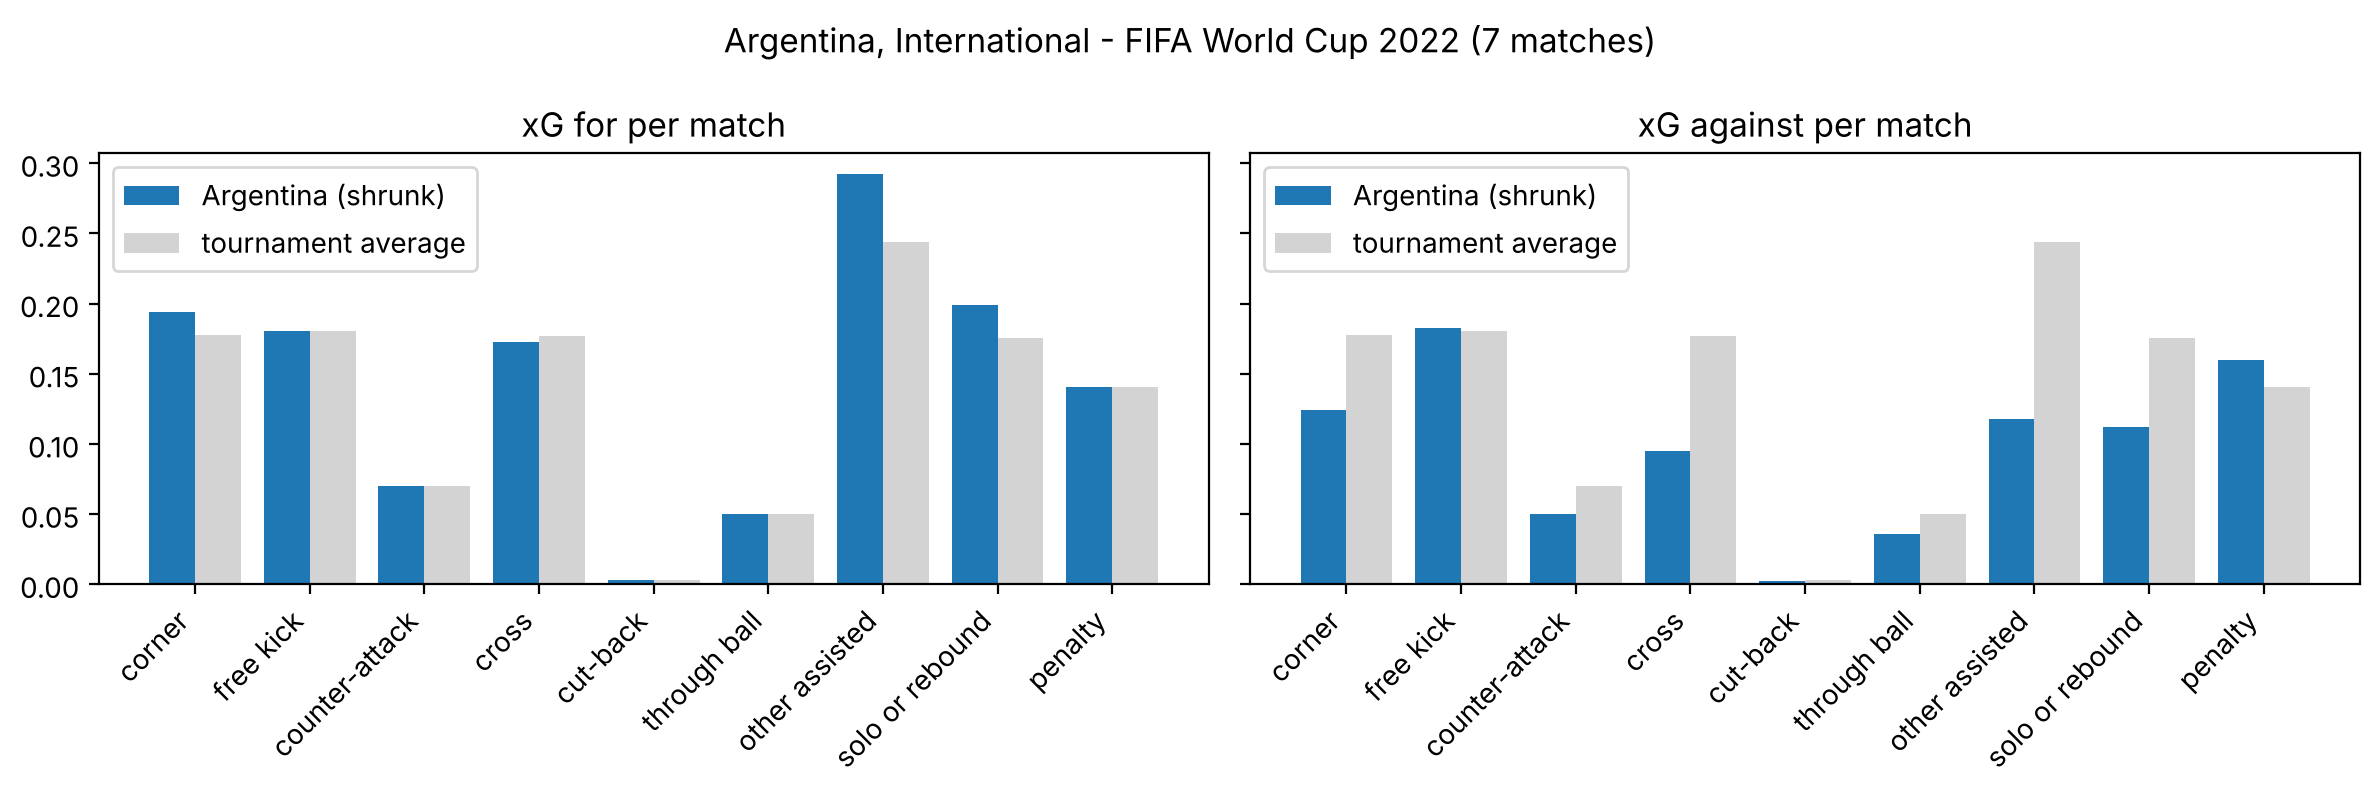

In [16]:
TEAM = "Argentina"
TOURNAMENT = "International - FIFA World Cup 2022"


def plotCard(cards, games, team, tournament):
    """Bar chart of a team's xG for and against by chance type."""
    card = cards[(cards["team"] == team) & (cards["tournament"] == tournament)].iloc[0]
    average = games[games["tournament"] == tournament][VALUES].mean()
    positions = np.arange(len(ORDER))
    width = 0.4

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, side in zip(axes, ["for", "against"]):
        teamValues = [card[side + " " + chance + " shrunk"] for chance in ORDER]
        averageValues = [average[side + " " + chance] for chance in ORDER]
        ax.bar(positions - width / 2, teamValues, width, label=team + " (shrunk)")
        ax.bar(positions + width / 2, averageValues, width, label="tournament average", color="lightgrey")
        ax.set_xticks(positions)
        ax.set_xticklabels(ORDER, rotation=45, ha="right")
        ax.set_title("xG " + side + " per match")
        ax.legend()
    fig.suptitle(team + ", " + tournament + " (" + str(int(card["matches"])) + " matches)")
    plt.tight_layout()
    return fig


fig = plotCard(cards, games, TEAM, TOURNAMENT)
plt.savefig("../outputs/team_card_example.png", dpi=150)
plt.show()

## The prediction test
Do a team's first 3 matches predict the rest of its tournament? Only teams with at least one match after their first 3 are used. For each value we compare three guesses for the rest:
1. the tournament average from the first 3 rounds (ignores the team),
2. the team's raw average over its first 3 matches,
3. the team's shrunk average over its first 3 matches, with k estimated from the first 3 rounds only.

The rest of the tournament is never used to make a guess.

In [17]:
FIRST = 3

early = games[games["game"] <= FIRST].copy()
late = games[games["game"] > FIRST].copy()

teamsWithRest = late.groupby(["tournament", "team"]).size().index
early = early.set_index(["tournament", "team"]).loc[teamsWithRest].reset_index()

print("Teams with matches after their first 3:", len(teamsWithRest))
print(late.groupby("tournament")["team"].nunique())

Teams with matches after their first 3: 80
tournament
Europe - UEFA Euro 2020                   16
Europe - UEFA Euro 2024                   16
Europe - UEFA Women's Euro 2022            8
Europe - UEFA Women's Euro 2025            8
International - FIFA World Cup 2022       16
International - Women's World Cup 2023    16
Name: team, dtype: int64


In [18]:
TESTED = ["xgFor", "xgAgainst", "for corner", "for free kick", "for counter-attack", "for cross", "for cut-back", "for through ball", "for solo or rebound"]


def predictionTest(early, late, value):
    """Error of the three guesses for one value."""
    actual = late.groupby(["tournament", "team"])[value].mean()
    raw = early.groupby(["tournament", "team"])[value].mean()
    tournamentMeans = early.groupby("tournament")[value].mean()
    average = pd.Series(actual.index.get_level_values("tournament").map(tournamentMeans).to_numpy(), index=actual.index)
    strength = shrinkStrength(early, value)
    shrunk = shrink(early, value, strength)

    raw = raw.loc[actual.index]
    shrunk = shrunk.loc[actual.index]

    row = {}
    row["value"] = value
    row["k"] = strength
    row["errorAverage"] = np.sqrt(((actual - average) ** 2).mean())
    row["errorRaw"] = np.sqrt(((actual - raw) ** 2).mean())
    row["errorShrunk"] = np.sqrt(((actual - shrunk) ** 2).mean())
    row["correlationRaw"] = np.corrcoef(raw, actual)[0, 1]
    return row

In [19]:
test = pd.DataFrame([predictionTest(early, late, value) for value in TESTED])
TIE = 0.001


def compare(row):
    """Is the shrunk guess better, the same or worse than the tournament average?"""
    gap = row["errorAverage"] - row["errorShrunk"]
    if gap > TIE:
        return "better"
    if gap < -TIE:
        return "worse"
    return "same"


test["shrunkVsAverage"] = test.apply(compare, axis=1)

print("Root mean squared error per match for each guess:")
print(test.round(3).to_string(index=False))

test.to_csv("../outputs/team_prediction_test.csv", index=False)

Root mean squared error per match for each guess:
              value     k  errorAverage  errorRaw  errorShrunk  correlationRaw shrunkVsAverage
              xgFor 6.742         0.745     0.754        0.696           0.436          better
          xgAgainst 6.119         0.915     0.920        0.891           0.285          better
         for corner 8.880         0.232     0.267        0.230           0.186          better
      for free kick   inf         0.151     0.201        0.151          -0.001            same
 for counter-attack   inf         0.110     0.129        0.110           0.164            same
          for cross 6.992         0.209     0.248        0.202           0.380          better
       for cut-back   inf         0.016     0.028        0.016          -0.046            same
   for through ball   inf         0.118     0.135        0.118           0.116            same
for solo or rebound   inf         0.244     0.290        0.244          -0.063            same


## Does it hold in every tournament?

In [20]:
def testByTournament(early, late, value):
    """The same test for one value, tournament by tournament."""
    rows = []
    for tournament in late["tournament"].unique():
        row = predictionTest(early[early["tournament"] == tournament], late[late["tournament"] == tournament], value)
        row["tournament"] = tournament
        row["teams"] = late[late["tournament"] == tournament]["team"].nunique()
        rows.append(row)
    return pd.DataFrame(rows)


byTournament = pd.concat([testByTournament(early, late, value) for value in ["xgFor", "xgAgainst"]])

print(byTournament[["value", "tournament", "teams", "errorAverage", "errorRaw", "errorShrunk", "correlationRaw"]].round(3).to_string(index=False))

    value                             tournament  teams  errorAverage  errorRaw  errorShrunk  correlationRaw
    xgFor                Europe - UEFA Euro 2020     16         0.648     0.909        0.720          -0.098
    xgFor                Europe - UEFA Euro 2024     16         0.618     0.645        0.607           0.196
    xgFor        Europe - UEFA Women's Euro 2022      8         1.044     0.958        0.892           0.713
    xgFor        Europe - UEFA Women's Euro 2025      8         0.820     0.646        0.718           0.730
    xgFor    International - FIFA World Cup 2022     16         0.588     0.494        0.588           0.577
    xgFor International - Women's World Cup 2023     16         0.865     0.828        0.865           0.701
xgAgainst                Europe - UEFA Euro 2020     16         0.786     0.816        0.778           0.226
xgAgainst                Europe - UEFA Euro 2024     16         0.692     0.678        0.642           0.408
xgAgainst        Eu

## Plot: first 3 matches against the rest

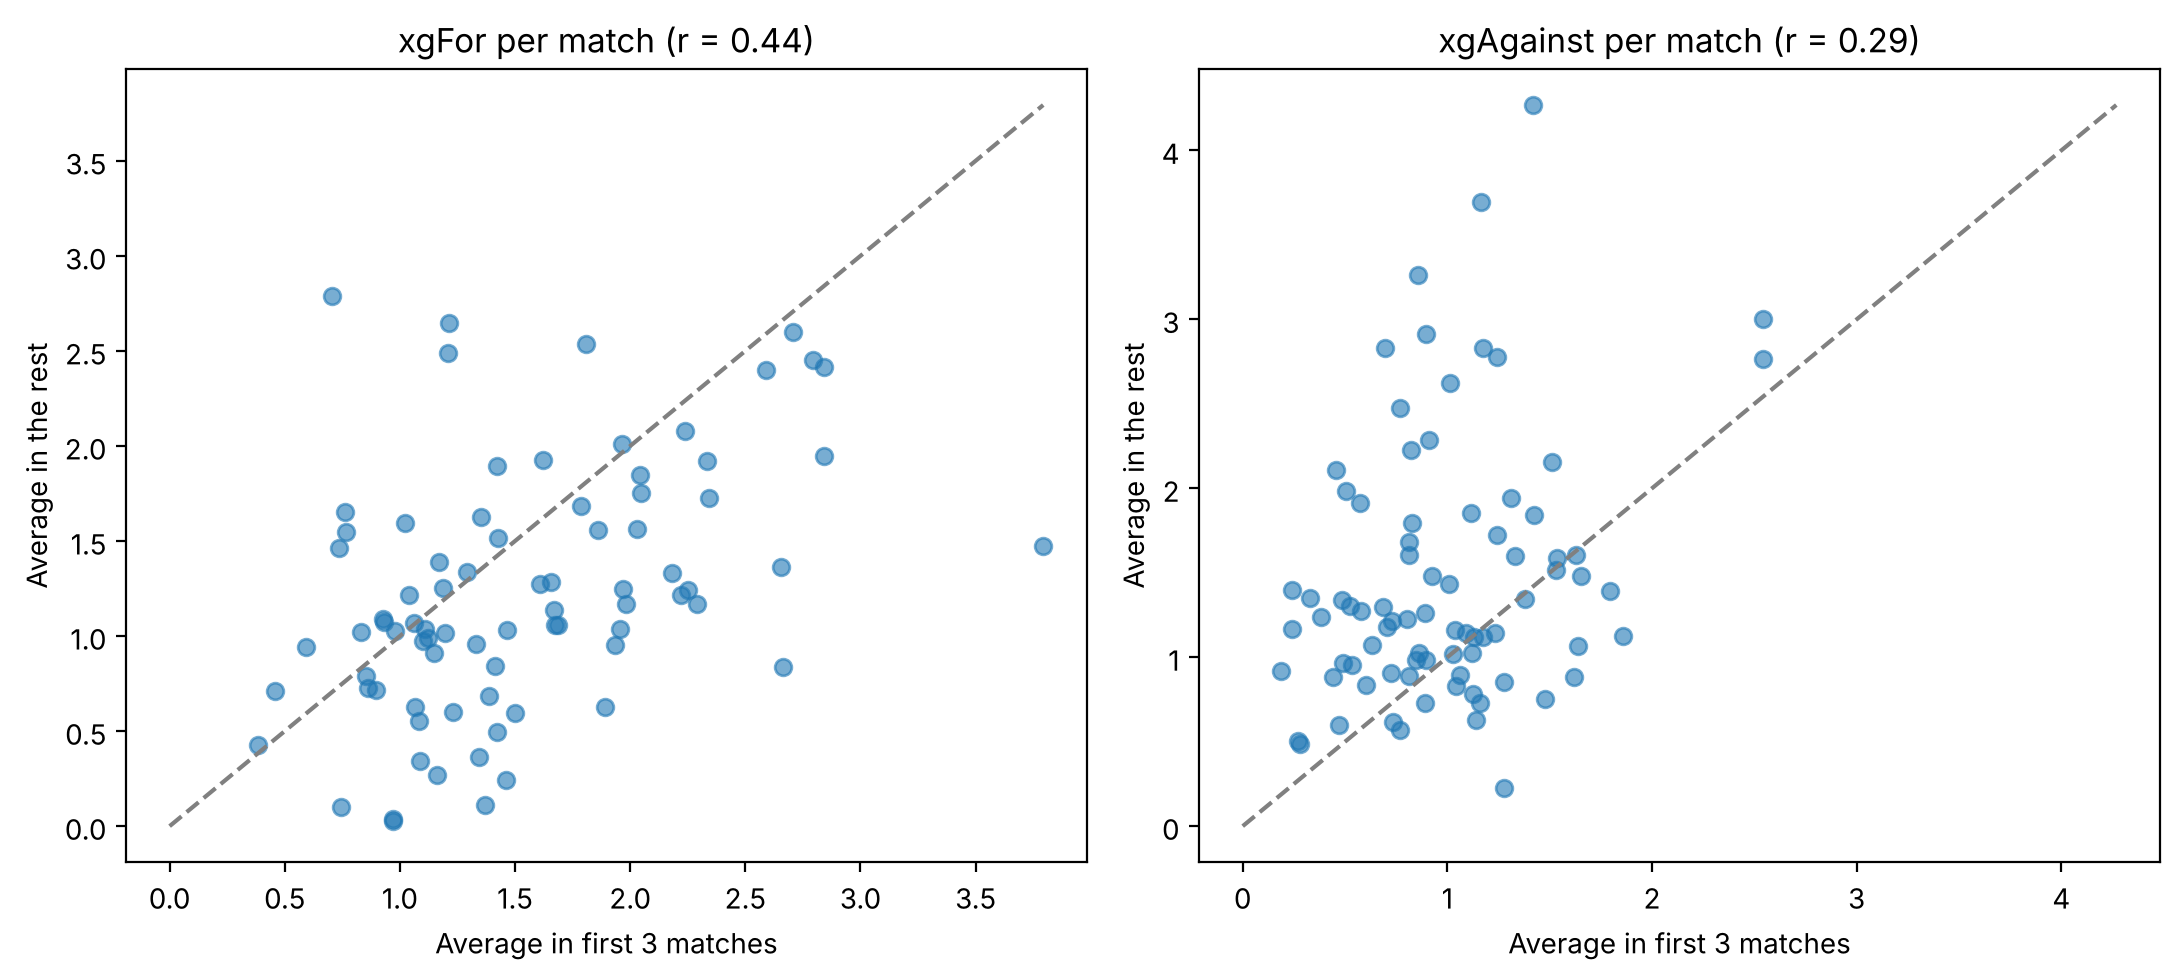

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, value in zip(axes, ["xgFor", "xgAgainst"]):
    actual = late.groupby(["tournament", "team"])[value].mean()
    raw = early.groupby(["tournament", "team"])[value].mean().loc[actual.index]
    ax.scatter(raw, actual, alpha=0.6)
    top = max(raw.max(), actual.max())
    ax.plot([0, top], [0, top], linestyle="--", color="grey")
    ax.set_xlabel("Average in first 3 matches")
    ax.set_ylabel("Average in the rest")
    ax.set_title(value + " per match (r = " + str(round(np.corrcoef(raw, actual)[0, 1], 2)) + ")")
plt.tight_layout()
plt.savefig("../outputs/team_prediction_test.png", dpi=150)
plt.show()

## What the test shows (with the StatsBomb xG stand-in)
- The shrunk first-3 average beats the tournament average for xG for and xG against, and for corner and cross chances. So the first 3 matches do say something about a team, but only after shrinking.
- The raw first-3 average is worse than the plain tournament average almost everywhere. Three matches are too few to take at face value.
- For the rarer chance types (free kicks, counters, cut-backs, through balls, solo chances) k is infinite: the differences between teams are no bigger than match-to-match noise, so the best guess is the tournament average.
- The link is stronger in the women's tournaments (correlation about 0.7 for xG for) than in the men's.

These numbers will change a little when Anish's xG replaces StatsBomb's, so rerun before writing VI Discussion.